<a href="https://colab.research.google.com/github/Praneethgajula01/aml-0026/blob/main/bias_variance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

np.random.seed(42)

X=np.linspace(0, 10, 40).reshape(-1, 1)

y=2+0.5*X[:, 0]**2 + np.random.normal(0,5, 40)

X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size=0.30, random_state=42
)

degrees=[1,2,10]

for degree in degrees:
  model=make_pipeline(
      PolynomialFeatures(degree=degree, include_bias=False),
      LinearRegression()
  )

  model.fit(X_train, y_train)
  train_prediction=model.predict(X_train)
  test_prediction=model.predict(X_test)

  train_mse=mean_squared_error(y_train, train_prediction)
  test_mse=mean_squared_error(y_test, test_prediction)


  print(f"Polynomial degree: {degree}")
  print(f"Training mse: {train_mse:.2f}")
  print(f"Testing mse: {test_mse:.2f}")


Polynomial degree: 1
Training mse: 42.90
Testing mse: 42.99
Polynomial degree: 2
Training mse: 20.44
Testing mse: 19.79
Polynomial degree: 10
Training mse: 12.89
Testing mse: 95.21


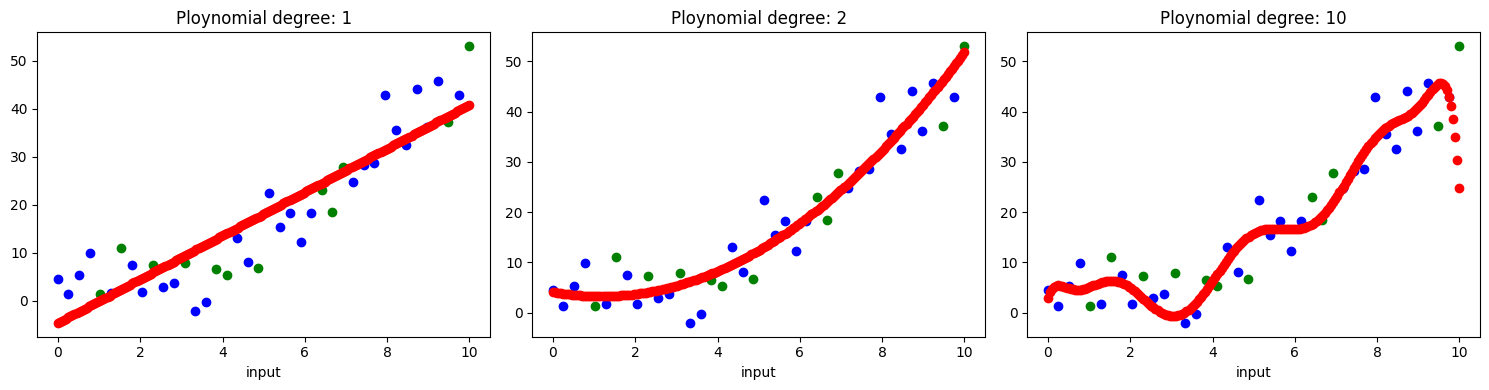

In [ ]:
import matplotlib.pyplot as plt

X_plot=np.linspace(0, 10, 200).reshape(-1, 1)

plt.figure(figsize=(15, 4))

for index, degree in enumerate(degrees):
  model=make_pipeline(
      PolynomialFeatures(degree=degree, include_bias=False),
      LinearRegression()
  )

  model.fit(X_train, y_train)
  y_plot=model.predict(X_plot)

  plt.subplot(1, 3, index+1)

  plt.scatter(X_train, y_train, color="blue", label="Training data")

  plt.scatter(X_test, y_test, color="green", label="Testing data")
  plt.scatter(X_plot, y_plot, color="red", label="Prediction")

  plt.title(f"Ploynomial degree: {degree}")
  plt.xlabel("input")
plt.tight_layout()
plt.show()

Cross Validation model selection


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error


for degree in range(1, 11):
  model=make_pipeline(
      PolynomialFeatures(degree=degree, include_bias=False),
      LinearRegression()
  )

  scores=cross_val_score(
      model, X, y, cv=5, scoring="neg_mean_squared_error"
  )

  mean_mse=-scores.mean()
  print(f"Degree {degree}: CV MSE={mean_mse:.2f}")

Degree 1: CV MSE=110.69
Degree 2: CV MSE=44.22
Degree 3: CV MSE=71.23
Degree 4: CV MSE=82.46
Degree 5: CV MSE=1348.27
Degree 6: CV MSE=11392.13
Degree 7: CV MSE=53226.76
Degree 8: CV MSE=99956.80
Degree 9: CV MSE=1196598.07
Degree 10: CV MSE=11490574.52


**FEATURE** **SELECTION**

In [ ]:
import pandas as pd
from sklearn.feature_selection import VarianceThreshold

X=pd.DataFrame({
    "constant_feature": [1,1,1,1,1],
    "almost_constant": [0,0,0,0,1],
    "useful_feature":[10, 20, 30, 40, 50]

})

selector=VarianceThreshold(threshold=0.2)

X_selected=selector.fit_transform(X)

selected_columns=X.columns[selector.get_support()]

print("Selected columns:", list(selected_columns))

Selected columns: ['useful_feature']


CORRELATION AMONG FEATURES


In [ ]:
import seaborn as selected_columns

data=pd.DataFrame({
    "study_hours": [1,2,3,4,5,6],
    "attendance": [50, 55, 65, 70, 80, 90],
    "previous_marks": [35, 40, 50, 55, 65, 75],
    "final_marks": [38, 45, 56, 59, 68, 79]
})

correlation_matrix=data.corr(numeric_only=True)



chi square

In [ ]:
from sklearn.datasets import load_breast_cancer

from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

data=load_breast_cancer()
X=data.data
y=data.target

X_non_negativ=MinMaxScaler().fit_transform(X)

selector=SelectKBest(score_func=chi2, k=5)
X_selected=selector.fit_transform(X_non_negativ, y)

selected_features=data.feature_names[selector.get_support()]

print("selected features:", selected_features)

selected features: ['mean concavity' 'mean concave points' 'worst perimeter' 'worst area'
 'worst concave points']


In [ ]:
from sklearn.datasets import load_iris

iris=load_iris()

X, y=iris.data, iris.target


X_select=SelectKBest(chi2, k=3).fit_transform(X, y)
X_select

array([[5.1, 1.4, 0.2],
       [4.9, 1.4, 0.2],
       [4.7, 1.3, 0.2],
       [4.6, 1.5, 0.2],
       [5. , 1.4, 0.2],
       [5.4, 1.7, 0.4],
       [4.6, 1.4, 0.3],
       [5. , 1.5, 0.2],
       [4.4, 1.4, 0.2],
       [4.9, 1.5, 0.1],
       [5.4, 1.5, 0.2],
       [4.8, 1.6, 0.2],
       [4.8, 1.4, 0.1],
       [4.3, 1.1, 0.1],
       [5.8, 1.2, 0.2],
       [5.7, 1.5, 0.4],
       [5.4, 1.3, 0.4],
       [5.1, 1.4, 0.3],
       [5.7, 1.7, 0.3],
       [5.1, 1.5, 0.3],
       [5.4, 1.7, 0.2],
       [5.1, 1.5, 0.4],
       [4.6, 1. , 0.2],
       [5.1, 1.7, 0.5],
       [4.8, 1.9, 0.2],
       [5. , 1.6, 0.2],
       [5. , 1.6, 0.4],
       [5.2, 1.5, 0.2],
       [5.2, 1.4, 0.2],
       [4.7, 1.6, 0.2],
       [4.8, 1.6, 0.2],
       [5.4, 1.5, 0.4],
       [5.2, 1.5, 0.1],
       [5.5, 1.4, 0.2],
       [4.9, 1.5, 0.2],
       [5. , 1.2, 0.2],
       [5.5, 1.3, 0.2],
       [4.9, 1.4, 0.1],
       [4.4, 1.3, 0.2],
       [5.1, 1.5, 0.2],
       [5. , 1.3, 0.3],
       [4.5, 1.3

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

data=load_iris()
X=data.data
y=data.target

selector=SelectKBest(score_func=f_classif, k=2)

X_selected=selector.fit_transform(X, y)

selected_features=np.array(data.feature_names)[selector.get_support()]

print("selected features:", selected_features)


selected features: ['petal length (cm)' 'petal width (cm)']
